# Sentiment Analysis: Classic NLP to LLMs

**Goal:** Compare simple sentiment analysis methods on GitHub comments.

We will compare:
1. **VADER** – uses a dictionary of positive and negative words.
2. **NLTK + Naive Bayes** – learns patterns from labelled examples.
3. **TF-IDF + Naive Bayes** – another traditional machine-learning approach.
4. **Claude API** – asks an LLM to classify the text.

All models use the same training data, test data, and hard-case sentences.

## Setup

In [8]:
import os
import re
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import nltk
from nltk import NaiveBayesClassifier, FreqDist
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords
from nltk.sentiment.util import mark_negation
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

## Import Data

In [5]:
import os

print("Current working directory:", os.getcwd())
print("Files in this folder:", os.listdir())

Current working directory: c:\Users\User\Downloads\DATA
Files in this folder: ['github_gold.csv', 'hard_cases.csv', 'sentiment_analysis.ipynb']


In [11]:
with open("github_gold.csv", "r", encoding="utf-8") as file:
    for i in range(10):
        print(f"Line {i+1}: {file.readline().strip()}")

Line 1: ID;Polarity;Text
Line 2: 4063186;neutral;"No. I still see the wrong twins.  * https://github.com/mojombo/jekyll/tree/gh-pages/news * https://github.com/mojombo/jekyll/tree/gh-pages/news/releases """
Line 3: 3894703;neutral;"Reverted."""
Line 4: 1971084;neutral;"You can leave a queue while in queue ? (before NEEDCONFIRMATION)"""
Line 5: 1827828;positive;"Didn't look at SpellTargetRestrictions XD"""
Line 6: 232603;neutral;"Not sure about what kind of line lengths the project adheres to, but this diff is showing so funky indentation here."""
Line 7: 3565454;positive;"@normanmaurer Nice catch ! Did you make the same on Netty 3 ?"""
Line 8: 3504879;neutral;"That's why I didn't close after sending the close frame.  On 06/26/2013 01:49 AM, Norman Maurer wrote: > > The client channel should wait for the close response of the server,  > as mention in the websockets rfc. So I think we should make to do it so... > """
Line 9: 3413199;neutral;"Build result for 78d8f05c218cab107255c4dc1a134

In [12]:
import pandas as pd

df = pd.read_csv("github_gold.csv", sep=";")

print(df.columns.tolist())
df.head()

['ID', 'Polarity', 'Text']


,ID,Polarity,Text
0,4063186,neutral,No. I still see the wrong twins. * https://gi...
1,3894703,neutral,"Reverted."""
2,1971084,neutral,You can leave a queue while in queue ? (before...
3,1827828,positive,"Didn't look at SpellTargetRestrictions XD"""
4,232603,neutral,Not sure about what kind of line lengths the p...


**Choose the correct column names.** Check the column names printed above. Change the two values below if your CSV uses different names.

For example, the text column contains the comments, and the label column contains `positive`, `negative`, or `neutral`.

In [14]:
TEXT_COL = "Text"
LABEL_COL = "Polarity"

df = df[[TEXT_COL, LABEL_COL]].copy()

df = df.rename(columns={
    TEXT_COL: "text",
    LABEL_COL: "label"
})

df.head()

,text,label
0,No. I still see the wrong twins. * https://gi...,neutral
1,"Reverted.""",neutral
2,You can leave a queue while in queue ? (before...,neutral
3,"Didn't look at SpellTargetRestrictions XD""",positive
4,Not sure about what kind of line lengths the p...,neutral


### Clean the data

In [15]:
# Remove rows with missing text or labels
df = df.dropna(subset=["text", "label"])

# Make text and labels easier to work with
df["text"] = df["text"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.strip().str.lower()

# Keep only the three sentiment labels
LABELS = ["negative", "neutral", "positive"]
df = df[df["label"].isin(LABELS)]

# Remove empty and duplicate comments
df = df[df["text"] != ""]
df = df.drop_duplicates(subset="text").reset_index(drop=True)

print("Rows after cleaning:", len(df))
df["label"].value_counts()

Rows after cleaning: 7122


label
neutral     3022
negative    2087
positive    2013
Name: count, dtype: int64

### Clean the text

In [16]:
def clean_text(text):
    text = re.sub(r"http\\S+|www\\.\\S+", " ", text)  # Remove links
    text = re.sub(r"@\\w+", " ", text)                  # Remove mentions
    text = text.replace("&amp;", "&")
    text = re.sub(r"\\s+", " ", text)                  # Remove extra spaces
    return text.strip()

df["clean"] = df["text"].apply(clean_text)
df[["text", "clean"]].head()

,text,clean
0,No. I still see the wrong twins. * https://gi...,No. I still see the wrong twins. * https://gi...
1,"Reverted.""","Reverted."""
2,You can leave a queue while in queue ? (before...,You can leave a queue while in queue ? (before...
3,"Didn't look at SpellTargetRestrictions XD""","Didn't look at SpellTargetRestrictions XD"""
4,Not sure about what kind of line lengths the p...,Not sure about what kind of line lengths the p...


## Train/Test Split
We use 80% of the data for training and 20% for testing. The test data is kept separate so we can fairly compare the models.

In [17]:
train, test = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

y_train = train["label"].to_numpy()
y_test = test["label"].to_numpy()

print(len(train), "training rows")
print(len(test), "testing rows")

5697 training rows
1425 testing rows


## Quick Data Check

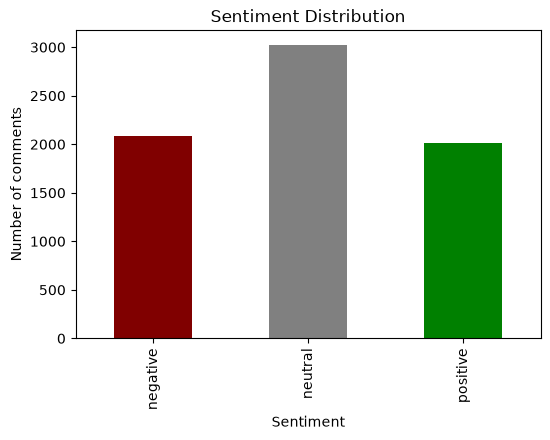

In [18]:
df["label"].value_counts().reindex(LABELS).plot.bar(
    color=["maroon", "gray", "green"],
    figsize=(6, 4)
)
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of comments")
plt.show()

In [19]:
for label in LABELS:
    print("\\n", label.upper())
    examples = train[train["label"] == label]["clean"].head(5)
    for text in examples:
        print("-", text)

\n NEGATIVE
- Dangit. I was on another branch where the history looked clean and didn't realize it when I pushed master."
- Oh sorry, I misrepresented the problem. It prints the headers every 5 minutes or if they've changed to help log parsers re-sync.  https://github.com/twitter/ostrich/blob/master/src/main/scala/com/twitter/ostrich/stats/W3CStats.scala#L45-60"
- Actually, turning `--follow` on unconditionally may be a bad idea. Git mantainers currently acknowledge that it is a 'bolted-on hack', and performs badly in complicated cases, like renaming a file in multiple branches and merging, or deleting file in a bra"
- @stof  you are right, thanks for explanation did not know about xdebug and functions calls :("
- Ugh, sucks that means inconsistent post presentation. Those timestamps are so ugly. :("
\n NEUTRAL
- @randx relying on very specific releases of MySQL sounds like a bad idea. Just my $0.02."
- Isn't this terribly inefficient? You're essentially loading and instantiating all t

## Hard Cases
The hard-case file contains examples that may confuse simple sentiment models. Make sure the file has `text`, `label`, and (if available) `category` columns.

In [20]:
hard = pd.read_csv("hard_cases.csv")
hard["clean"] = hard["text"].astype(str).apply(clean_text)
y_hard = hard["label"].astype(str).str.lower().to_numpy()

print("Number of hard cases:", len(hard))
hard.head()

Number of hard cases: 30


,text,label,category,source,clean
0,Kill the process and restart the service.,neutral,jargon,starter,Kill the process and restart the service.
1,I'll remove the dead code and the deprecated f...,neutral,jargon,starter,I'll remove the dead code and the deprecated f...
2,The null pointer exception is thrown when the ...,neutral,jargon,starter,The null pointer exception is thrown when the ...
3,Run the test suite and check the failed cases ...,neutral,jargon,starter,Run the test suite and check the failed cases ...
4,Aggressive inlining is enabled by default at -O3.,neutral,jargon,starter,Aggressive inlining is enabled by default at -O3.


## Evaluate Every Model
This function calculates accuracy and macro-F1 on the test data, plus accuracy on the hard cases.

In [22]:
results = {}
preds = {}
hard_preds = {}

def evaluate(name, test_predictions, hard_predictions):
    test_predictions = np.array(test_predictions)
    hard_predictions = np.array(hard_predictions)

    preds[name] = test_predictions
    hard_preds[name] = hard_predictions

    results[name] = {
        "Accuracy": accuracy_score(y_test, test_predictions),
        "Macro-F1": f1_score(y_test, test_predictions, labels=LABELS, average="macro"),
        "Hard-case accuracy": accuracy_score(y_hard, hard_predictions)
    }

    print("Results for:", name)
    print(classification_report(
        y_test, test_predictions,
        labels=LABELS,
        zero_division=0
    ))
    print("Hard-case accuracy:", round(results[name]["Hard-case accuracy"], 3))

## Model 1: VADER
VADER uses a dictionary of words and rules. It does not need training data.

In [23]:
vader = SentimentIntensityAnalyzer()

examples = [
    "Great fix, thanks!",
    "This is not good.",
    "Kill the process and restart the service.",
    "Thanks, that fixed the memory leak."
]

for sentence in examples:
    print(sentence)
    print(vader.polarity_scores(sentence))
    print()

Great fix, thanks!
{'neg': 0.0, 'neu': 0.121, 'pos': 0.879, 'compound': 0.807}

This is not good.
{'neg': 0.445, 'neu': 0.555, 'pos': 0.0, 'compound': -0.3412}

Kill the process and restart the service.
{'neg': 0.439, 'neu': 0.561, 'pos': 0.0, 'compound': -0.6908}

Thanks, that fixed the memory leak.
{'neg': 0.258, 'neu': 0.43, 'pos': 0.312, 'compound': 0.128}



### Convert VADER scores into sentiment labels

In [24]:
def vader_label(text):
    score = vader.polarity_scores(text)["compound"]

    if score >= 0.05:
        return "positive"
    elif score <= -0.05:
        return "negative"
    else:
        return "neutral"

vader_test = test["clean"].apply(vader_label)
vader_hard = hard["clean"].apply(vader_label)

evaluate("VADER", vader_test, vader_hard)

Results for: VADER
              precision    recall  f1-score   support

    negative       0.62      0.66      0.64       417
     neutral       0.71      0.36      0.48       605
    positive       0.50      0.84      0.63       403

    accuracy                           0.59      1425
   macro avg       0.61      0.62      0.58      1425
weighted avg       0.63      0.59      0.57      1425

Hard-case accuracy: 0.367


## Model 2: NLTK + Naive Bayes
This model learns which words are commonly associated with each sentiment.

In [25]:
nltk.download("stopwords")

tokenizer = TweetTokenizer(
    preserve_case=False,
    reduce_len=True,
    strip_handles=True
)

stop_words = set(stopwords.words("english"))

# Keep these words because they can change the meaning
keep_words = {"no", "nor", "not", "very", "too", "against"}
stop_words = stop_words - keep_words

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [26]:
def text_tokens(text):
    words = tokenizer.tokenize(text)
    words = mark_negation(words)

    clean_words = []
    for word in words:
        word_without_negation = word.replace("_NEG", "")

        if word_without_negation not in stop_words and re.search(r"\\w", word):
            clean_words.append(word)

    return clean_words

text_tokens("I do NOT like this change. The fix was very slow!")

[]

### Prepare the training words

In [27]:
train_tokens = [text_tokens(text) for text in train["clean"]]
test_tokens = [text_tokens(text) for text in test["clean"]]
hard_tokens = [text_tokens(text) for text in hard["clean"]]

# Find the 3,000 most common words in the training data
word_frequency = FreqDist(word for words in train_tokens for word in words)
vocabulary = {word for word, count in word_frequency.most_common(3000)}

print("Number of words in vocabulary:", len(vocabulary))

Number of words in vocabulary: 0


### Create features and train the model

In [28]:
def make_features(words):
    features = {}

    for word in words:
        if word in vocabulary:
            features[word] = True

    return features

train_set = []
for words, label in zip(train_tokens, y_train):
    train_set.append((make_features(words), label))

nb_model = NaiveBayesClassifier.train(train_set)

nb_model.show_most_informative_features(15)

Most Informative Features


In [29]:
nb_test = [nb_model.classify(make_features(words)) for words in test_tokens]
nb_hard = [nb_model.classify(make_features(words)) for words in hard_tokens]

evaluate("NLTK + Naive Bayes", nb_test, nb_hard)

Results for: NLTK + Naive Bayes
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00       417
     neutral       0.42      1.00      0.60       605
    positive       0.00      0.00      0.00       403

    accuracy                           0.42      1425
   macro avg       0.14      0.33      0.20      1425
weighted avg       0.18      0.42      0.25      1425

Hard-case accuracy: 0.333


## Model 3: TF-IDF + Naive Bayes
TF-IDF gives more importance to words that are useful in a particular comment and less importance to words that appear everywhere.

In [30]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)

X_train = tfidf.fit_transform(train["clean"])
X_test = tfidf.transform(test["clean"])
X_hard = tfidf.transform(hard["clean"])

tfidf_model = MultinomialNB()
tfidf_model.fit(X_train, y_train)

tfidf_test = tfidf_model.predict(X_test)
tfidf_hard = tfidf_model.predict(X_hard)

evaluate("TF-IDF + Naive Bayes", tfidf_test, tfidf_hard)

Results for: TF-IDF + Naive Bayes
              precision    recall  f1-score   support

    negative       0.79      0.50      0.61       417
     neutral       0.61      0.96      0.75       605
    positive       0.91      0.48      0.63       403

    accuracy                           0.69      1425
   macro avg       0.77      0.65      0.66      1425
weighted avg       0.75      0.69      0.67      1425

Hard-case accuracy: 0.467


## Model 4: Claude API (LLM)

This model sends each comment to Claude and asks it to return `positive`, `negative`, or `neutral`.

**API key:** Create a file named `.env` in the same folder as this notebook. Add your key like this:

```text
ANTHROPIC_API_KEY=your_actual_api_key
```

Do not put your real API key directly in the notebook or upload the `.env` file to GitHub.

In [31]:
from dotenv import load_dotenv
import anthropic

# Read the API key from the .env file
load_dotenv(".env")

api_key = os.getenv("ANTHROPIC_API_KEY")

if not api_key:
    raise ValueError("API key not found. Check your .env file.")

client = anthropic.Anthropic(api_key=api_key)

print("API key loaded successfully.")

ValueError: API key not found. Check your .env file.

### Ask Claude to classify one comment

In [ ]:
MODEL = "claude-haiku-5-5"

def claude_sentiment(text):
    response = client.messages.create(
        model=MODEL,
        max_tokens=10,
        messages=[
            {
                "role": "user",
                "content": (
                    "Classify the sentiment of this software comment. "
                    "Reply with only one word: positive, negative, or neutral.\\n\\n"
                    + text
                )
            }
        ]
    )

    answer = response.content[0].text.strip().lower()

    if answer not in LABELS:
        return "neutral"

    return answer

# Test with one comment first
claude_sentiment("Great fix, thanks for solving this issue!")

### Run Claude on the test and hard-case data

**Important:** Each comment sent to Claude may cost money. First test with a small number of comments. The example below uses only 5 test comments.

In [ ]:
# Small test first: 5 comments
for text in test["clean"].head(5):
    print(text)
    print("Claude:", claude_sentiment(text))
    print()

If the small test works, run the full test and hard-case predictions. This sends one API request for every comment, so it may cost money and take time.

In [ ]:
claude_test = [claude_sentiment(text) for text in test["clean"]]
claude_hard = [claude_sentiment(text) for text in hard["clean"]]

evaluate("Claude API", claude_test, claude_hard)

## Compare All Models

In [32]:
summary = pd.DataFrame(results).T
summary = summary.sort_values("Macro-F1", ascending=False).round(3)
summary

,Accuracy,Macro-F1,Hard-case accuracy
TF-IDF + Naive Bayes,0.691,0.663,0.467
VADER,0.585,0.584,0.367
NLTK + Naive Bayes,0.425,0.199,0.333


In [ ]:
summary[["Accuracy", "Macro-F1", "Hard-case accuracy"]].plot.bar(
    figsize=(10, 5),
    rot=20
)
plt.title("Sentiment Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.show()

### Confusion Matrices
A confusion matrix shows which sentiment labels each model predicts correctly or incorrectly.

In [ ]:
for name, predictions in preds.items():
    print(name)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=LABELS,
        cmap="Blues"
    )
    plt.show()

## Error Analysis
Look at examples where the models made incorrect predictions. Try to understand whether the text is unclear, sarcastic, technical, or incorrectly labelled.

In [33]:
errors = test[["text", "label"]].copy()

for name, predictions in preds.items():
    errors[name] = predictions

errors.head(10)

,text,label,VADER,NLTK + Naive Bayes,TF-IDF + Naive Bayes
394,I think lens flare should be removed from the ...,positive,positive,neutral,neutral
4322,API here is a bit weird. cb functions should ...,negative,negative,neutral,neutral
3680,Fixed to be: ``` ruby if addr && !addr.empty?...,neutral,neutral,neutral,neutral
1856,"it was really useless here""",negative,negative,neutral,negative
2779,"Awesome, already implemented Zelda-Like :heart...",positive,positive,neutral,positive
4549,"damn I need to configure spelling in emacs, th...",negative,negative,neutral,negative
5393,"Spp, is necessary update the table """"lfg_dunge...",neutral,positive,neutral,neutral
7031,This is original code https://github.com/symfo...,neutral,positive,neutral,neutral
811,"i don't get it, why do you override DateTime#t...",neutral,positive,neutral,neutral
5719,"ah, `#{shared_path}/log` is at least predictab...",neutral,positive,neutral,neutral


In [34]:
# Show comments that every model predicted incorrectly
wrong_in_every_model = errors.copy()

for name in preds:
    wrong_in_every_model = wrong_in_every_model[
        wrong_in_every_model[name] != wrong_in_every_model["label"]
    ]

wrong_in_every_model.head(10)

,text,label,VADER,NLTK + Naive Bayes,TF-IDF + Naive Bayes
4481,I'm concerned that this code is too functional...,negative,positive,neutral,neutral
2193,"mergefail! :'(""",negative,neutral,neutral,neutral
6007,"Can you write the """"hack"""" for me ? :p I need ...",positive,negative,neutral,neutral
175,A okey. I should start looking at the JavaScri...,positive,neutral,neutral,neutral
5283,"with this line, it is hack""",negative,neutral,neutral,neutral
1084,"Hate to add noise, but I would really prefer t...",negative,positive,neutral,neutral
1106,@randx Is there a specific reason why these go...,negative,positive,neutral,neutral
5193,"How about fixing hashcode too? :/""",negative,neutral,neutral,neutral
5331,"Shauren did forget something ... *screenshot* :p""",positive,negative,neutral,neutral
890,"That's why I do +1 on this change :)""",positive,neutral,neutral,neutral
